In [14]:
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

path = kagglehub.dataset_download("kartik2112/fraud-detection")

# Загружаем данные
df = pd.read_csv(f"{path}/fraudTrain.csv", index_col=0)

print(df.shape)
print(df[['amt', 'category', 'is_fraud']].head())
print(df['is_fraud'].value_counts(normalize=True))

Using Colab cache for faster access to the 'fraud-detection' dataset.
(1296675, 22)
      amt       category  is_fraud
0    4.97       misc_net         0
1  107.23    grocery_pos         0
2  220.11  entertainment         0
3   45.00  gas_transport         0
4   41.96       misc_pos         0
is_fraud
0    0.994211
1    0.005789
Name: proportion, dtype: float64


In [16]:
print(df.sample(10))

        trans_date_trans_time               cc_num  \
1105930   2020-04-05 13:40:17        4393520897625   
653656    2019-10-05 19:32:50        4169388510116   
865809    2019-12-19 01:24:31     6011348830550197   
290595    2019-05-23 05:41:31         676275912597   
7106      2019-01-05 16:39:32        4306630852918   
881329    2019-12-22 13:41:32     6011438889172900   
629303    2019-09-24 09:41:06       36913587729122   
1002953   2020-02-16 01:17:42  4890424426862856940   
811788    2019-12-07 10:56:47        4988304376504   
300359    2019-05-26 17:56:15       30044330818990   

                                     merchant       category     amt    first  \
1105930                  fraud_Beier and Sons           home   81.30  Charles   
653656                        fraud_Beier LLC  entertainment   13.72   Marcia   
865809           fraud_Olson, Becker and Koch  gas_transport   77.36   Samuel   
290595                  fraud_Vandervort-Funk    grocery_pos   94.84   Edward   


In [18]:
df.describe()

,cc_num,amt,zip,lat,long,city_pop,unix_time,merch_lat,merch_long,is_fraud
count,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06
mean,4.171920e+17,7.035104e+01,4.880067e+04,3.853762e+01,-9.022634e+01,8.882444e+04,1.349244e+09,3.853734e+01,-9.022646e+01,5.788652e-03
std,1.308806e+18,1.603160e+02,2.689322e+04,5.075808e+00,1.375908e+01,3.019564e+05,1.284128e+07,5.109788e+00,1.377109e+01,7.586269e-02
min,6.041621e+10,1.000000e+00,1.257000e+03,2.002710e+01,-1.656723e+02,2.300000e+01,1.325376e+09,1.902779e+01,-1.666712e+02,0.000000e+00
25%,1.800429e+14,9.650000e+00,2.623700e+04,3.462050e+01,-9.679800e+01,7.430000e+02,1.338751e+09,3.473357e+01,-9.689728e+01,0.000000e+00
50%,3.521417e+15,4.752000e+01,4.817400e+04,3.935430e+01,-8.747690e+01,2.456000e+03,1.349250e+09,3.936568e+01,-8.743839e+01,0.000000e+00
75%,4.642255e+15,8.314000e+01,7.204200e+04,4.194040e+01,-8.015800e+01,2.032800e+04,1.359385e+09,4.195716e+01,-8.023680e+01,0.000000e+00
max,4.992346e+18,2.894890e+04,9.978300e+04,6.669330e+01,-6.795030e+01,2.906700e+06,1.371817e+09,6.751027e+01,-6.695090e+01,1.000000e+00


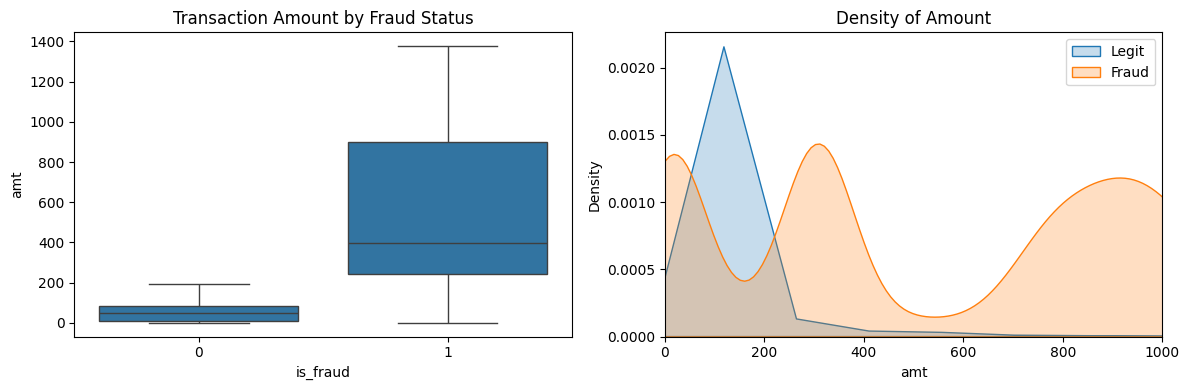

In [2]:
# поиск крупных движений
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
sns.boxplot(x='is_fraud', y='amt', data=df, showfliers=False)
plt.title('Transaction Amount by Fraud Status')

plt.subplot(1, 2, 2)
sns.kdeplot(data=df[df['is_fraud']==0]['amt'], label='Legit', fill=True)
sns.kdeplot(data=df[df['is_fraud']==1]['amt'], label='Fraud', fill=True)
plt.xlim(0, 1000)
plt.legend()
plt.title('Density of Amount')
plt.tight_layout()
plt.show()

Большинство мошеннических транзакций приходится на суммы транзакций (amt) свыше 200, т.е. amt > 200 - первый красный флаг.
Большинство нормальных транзакций меньше 200 - это обычные бытовые траты типа кафе и магазинов.

count    1.289169e+06
mean     6.766711e+01
std      1.540080e+02
min      1.000000e+00
25%      9.610000e+00
50%      4.728000e+01
75%      8.254000e+01
90%      1.342100e+02
99%      4.863032e+02
max      2.894890e+04
Name: amt, dtype: float64


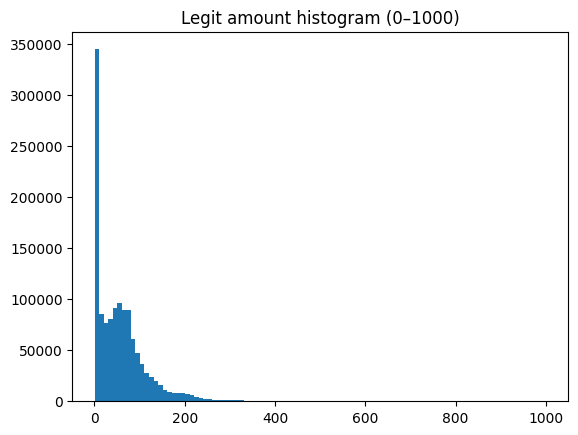

In [4]:
legit = df[df['is_fraud']==0]['amt']
print(legit.describe(percentiles=[.25,.5,.75,.9,.99]))
# гистограмма без KDE, чтобы посмотреть, где реальная масса
plt.hist(legit[legit < 1000], bins=100)
plt.title('Legit amount histogram (0–1000)')
plt.show()

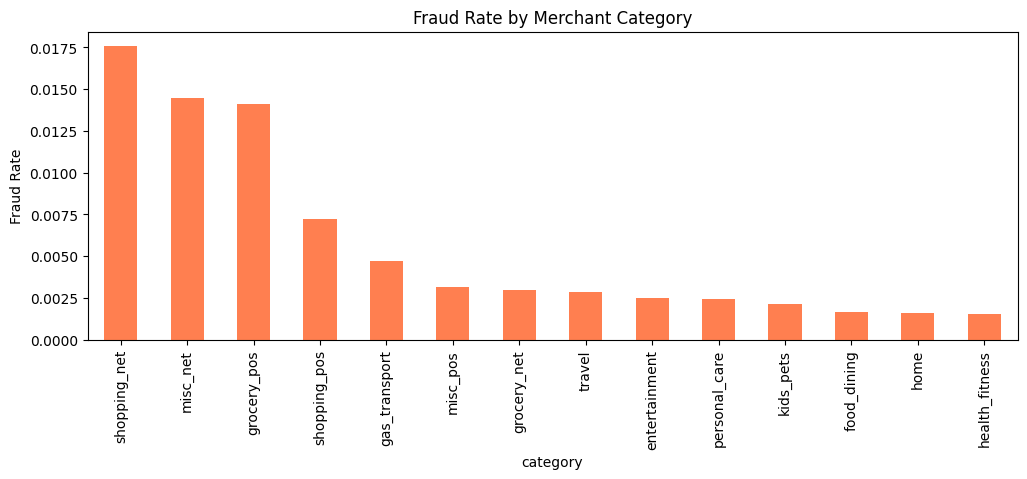

category
shopping_net      0.017561
misc_net          0.014458
grocery_pos       0.014098
shopping_pos      0.007225
gas_transport     0.004694
misc_pos          0.003139
grocery_net       0.002948
travel            0.002864
entertainment     0.002478
personal_care     0.002424
kids_pets         0.002114
food_dining       0.001651
home              0.001608
health_fitness    0.001549
Name: is_fraud, dtype: float64


In [6]:
# проверим, есть ли наиболее уязвимые категории
fraud_by_category = df.groupby('category')['is_fraud'].mean().sort_values(ascending=False)
fraud_by_category.plot(kind='bar', figsize=(12, 4), color='coral')
plt.title('Fraud Rate by Merchant Category')
plt.ylabel('Fraud Rate')
plt.show()

print(fraud_by_category)

И у нас есть безусловный лидер по мошенническим операциям: покупки в интернете

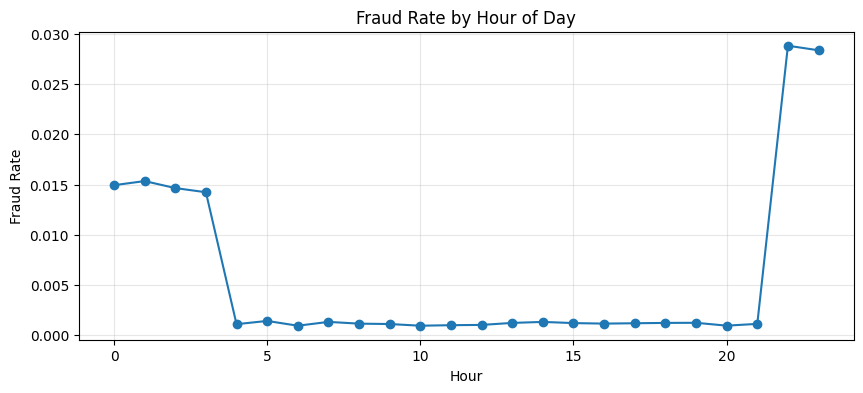

In [7]:
# проверим, есть ли закономерности во времени операций
df['hour'] = pd.to_datetime(df['trans_date_trans_time']).dt.hour
fraud_rate_by_hour = df.groupby('hour')['is_fraud'].mean()
fraud_rate_by_hour.plot(kind='line', marker='o', figsize=(10, 4))
plt.title('Fraud Rate by Hour of Day')
plt.xlabel('Hour')
plt.ylabel('Fraud Rate')
plt.grid(True, alpha=0.3)
plt.show()

Больше всего мошеннических операций видим поздним вечером, в ночные часы уровень немного снижается, с 4 утра и до 9 вечера уровень низкий

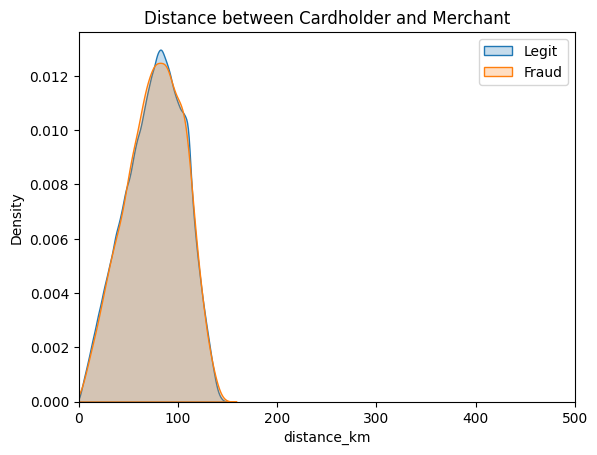

In [8]:
# проверим, есть ли закономерности в несоответветствии местоположения обычных и мошеннических транзакций с помощью простого расстояния по Хаверсину (приблизительно)
from math import radians, sin, cos, sqrt, atan2

def haversine(lat1, lon1, lat2, lon2):
    R = 6371  # km
    dlat = radians(lat2 - lat1)
    dlon = radians(lon2 - lon1)
    a = sin(dlat/2)**2 + cos(radians(lat1)) * cos(radians(lat2)) * sin(dlon/2)**2
    return R * 2 * atan2(sqrt(a), sqrt(1-a))

df['distance_km'] = df.apply(lambda row: haversine(row['lat'], row['long'],
                                                    row['merch_lat'], row['merch_long']), axis=1)

sns.kdeplot(data=df[df['is_fraud']==0]['distance_km'], label='Legit', fill=True)
sns.kdeplot(data=df[df['is_fraud']==1]['distance_km'], label='Fraud', fill=True)
plt.xlim(0, 500)
plt.legend()
plt.title('Distance between Cardholder and Merchant')
plt.show()

In [9]:
df['dist_bin'] = pd.qcut(df['distance_km'], 20, duplicates='drop')
fraud_by_dist = df.groupby('dist_bin')['is_fraud'].agg(['mean', 'count'])
print(fraud_by_dist)


                        mean  count
dist_bin                           
(0.0213, 24.741]    0.005337  64834
(24.741, 35.011]    0.005907  64834
(35.011, 42.835]    0.005645  64834
(42.835, 49.443]    0.005537  64833
(49.443, 55.335]    0.006154  64834
(55.335, 60.571]    0.005630  64834
(60.571, 65.471]    0.006062  64833
(65.471, 69.965]    0.006154  64834
(69.965, 74.196]    0.005815  64834
(74.196, 78.232]    0.005969  64834
(78.232, 82.117]    0.005599  64833
(82.117, 85.978]    0.005661  64834
(85.978, 89.957]    0.005861  64834
(89.957, 94.118]    0.005784  64833
(94.118, 98.503]    0.005923  64834
(98.503, 103.09]    0.005445  64834
(103.09, 107.797]   0.006201  64833
(107.797, 112.821]  0.005583  64834
(112.821, 120.495]  0.005861  64834
(120.495, 152.117]  0.005645  64834


/tmp/ipykernel_3613/924129002.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  fraud_by_dist = df.groupby('dist_bin')['is_fraud'].agg(['mean', 'count'])


<Axes: xlabel='distance_km', ylabel='Density'>

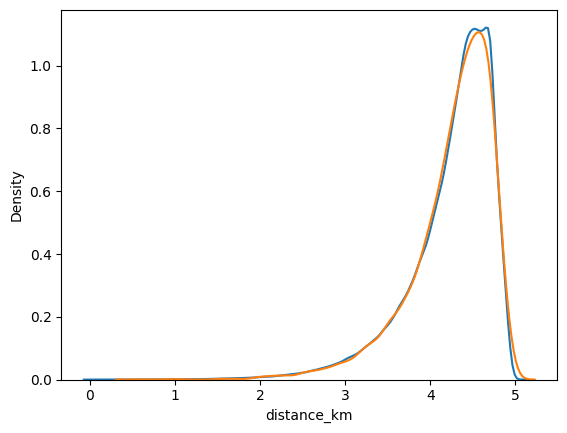

In [10]:
sns.kdeplot(data=np.log1p(df[df['is_fraud']==0]['distance_km']), label='Legit')
sns.kdeplot(data=np.log1p(df[df['is_fraud']==1]['distance_km']), label='Fraud')

In [11]:
user_stats = df.groupby('cc_num')['distance_km'].agg(['median', 'std']).rename(
    columns={'median':'user_med', 'std':'user_std'})
df = df.merge(user_stats, on='cc_num', how='left')
df['dist_zscore'] = (df['distance_km'] - df['user_med']) / df['user_std'].replace(0, np.nan)

# AUC двух версий признака
from sklearn.metrics import roc_auc_score
print('AUC abs:',   roc_auc_score(df.is_fraud, df.distance_km.fillna(0)))
print('AUC zscore:', roc_auc_score(df.is_fraud, df.dist_zscore.fillna(0)))

AUC abs: 0.5007556224978417
AUC zscore: 0.5015879539097694


Вероятно, в наших синтетических данных это не самый полезный признак, т.к. нет значительных отклонений, на которорые можно было бы опираться.

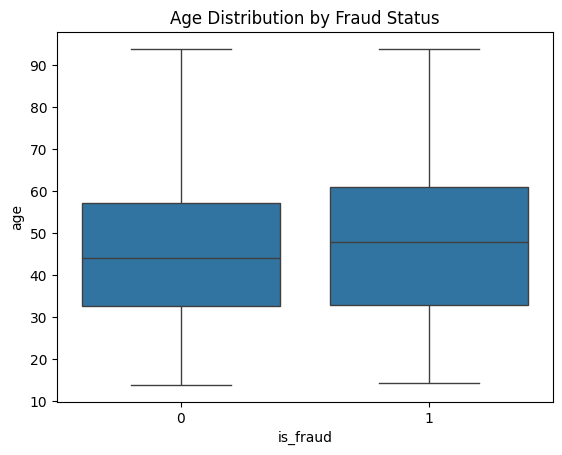

In [12]:
# Проверим, есть ли более уязвимый возраст
df['dob'] = pd.to_datetime(df['dob'])
df['trans_date_trans_time'] = pd.to_datetime(df['trans_date_trans_time'])
df['age'] = (df['trans_date_trans_time'] - df['dob']).dt.days / 365.25

sns.boxplot(x='is_fraud', y='age', data=df, showfliers=False)
plt.title('Age Distribution by Fraud Status')
plt.show()

Похоже, что возраст тоже не самый полезный признак, хотя у людей около 60 немного выше риск подвергнуться мошшеническим операциям.

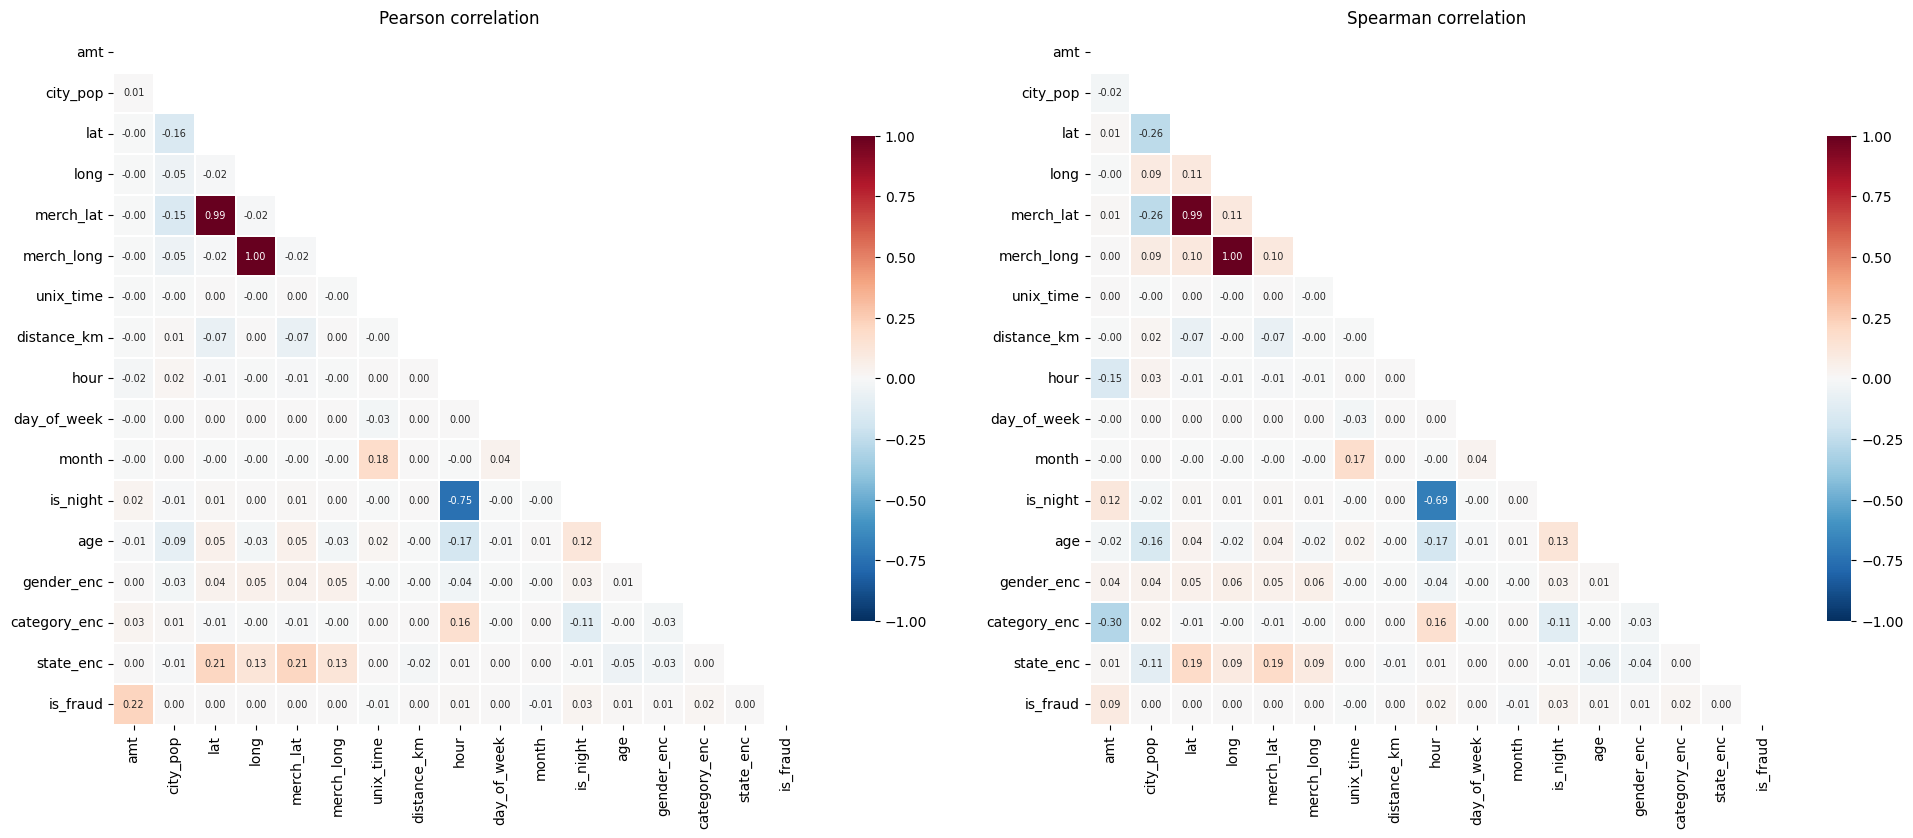

Топ корреляций с is_fraud (Pearson):
amt             0.219404
is_night        0.029622
category_enc    0.020205
hour            0.013799
month          -0.012409
age             0.012270
gender_enc      0.007642
unix_time      -0.005078
city_pop        0.002136
lat             0.001894
merch_lat       0.001741
day_of_week     0.001739
state_enc       0.001730
merch_long      0.001721
long            0.001721
distance_km     0.000403
Name: is_fraud, dtype: float64


In [21]:
# Поробуем посмотреть на корреляцию через формулы
df['trans_date_trans_time'] = pd.to_datetime(df['trans_date_trans_time'])
df['dob'] = pd.to_datetime(df['dob'])

df['hour']        = df['trans_date_trans_time'].dt.hour
df['day_of_week'] = df['trans_date_trans_time'].dt.dayofweek
df['month']       = df['trans_date_trans_time'].dt.month
df['is_night']    = df['hour'].isin([0,1,2,3,4,5]).astype(int)
df['age']         = (df['trans_date_trans_time'] - df['dob']).dt.days / 365.25

def haversine(lat1, lon1, lat2, lon2):
    R = 6371
    dlat, dlon = radians(lat2-lat1), radians(lon2-lon1)
    a = sin(dlat/2)**2 + cos(radians(lat1))*cos(radians(lat2))*sin(dlon/2)**2
    return R * 2 * atan2(sqrt(a), sqrt(1-a))

df['distance_km'] = df.apply(
    lambda r: haversine(r['lat'], r['long'], r['merch_lat'], r['merch_long']), axis=1)

# Кодирование категориальных признаков
# gender: 0/1; category: label-encode; state: label-encode
df['gender_enc']   = (df['gender'] == 'M').astype(int)
df['category_enc'] = df['category'].astype('category').cat.codes
df['state_enc']    = df['state'].astype('category').cat.codes

# Набор числовых признаков для корреляции
num_cols = [
    'amt', 'city_pop', 'lat', 'long', 'merch_lat', 'merch_long',
    'unix_time', 'distance_km', 'hour', 'day_of_week', 'month',
    'is_night', 'age', 'gender_enc', 'category_enc', 'state_enc',
    'is_fraud'
]
corr_df = df[num_cols].copy()

# Матрица корреляций
corr_pearson  = corr_df.corr(method='pearson')
corr_spearman = corr_df.corr(method='spearman')

# Визуализация
mask = np.triu(np.ones_like(corr_pearson, dtype=bool))  # скрываем верхний треугольник как бесполезный

fig, axes = plt.subplots(1, 2, figsize=(20, 8))

sns.heatmap(corr_pearson, mask=mask, cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            annot=True, fmt='.2f', annot_kws={'size': 7},
            square=True, linewidths=0.3, cbar_kws={'shrink': .7}, ax=axes[0])
axes[0].set_title('Pearson correlation')

sns.heatmap(corr_spearman, mask=mask, cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            annot=True, fmt='.2f', annot_kws={'size': 7},
            square=True, linewidths=0.3, cbar_kws={'shrink': .7}, ax=axes[1])
axes[1].set_title('Spearman correlation')

plt.tight_layout()
plt.show()

# Топ корреляций с целевой переменной
target_corr = corr_pearson['is_fraud'].drop('is_fraud').sort_values(key=abs, ascending=False)
print("Топ корреляций с is_fraud (Pearson):")
print(target_corr)

Результаты подвтерждают, что следует делать акцент на крупных суммах, ночных операциях и определенных категориях, и быть внимательнее к операциям пожилых людей.